# Prelab 07: Introduction to RC circuits

In [ ]:
# Run me to import the relevant libraries

%reset -f

import numpy as np
import data_entry2
from phys119_functions import *

*Lab 07 is a Foundations Lab that focuses on you gaining practice using an oscilloscope, which is a device that measures and graphs voltage as a function of time. Developing some initial proficiency with the oscilloscope is one of the primary learning goals for this lab.*

This prelab provides you with the following resources to help you prepare for Lab 07:
- a quick review of some important course concepts;
- an overview of the physics behind Lab 07 (RC Circuits I);
- a guide for the measurements needed to determine the time constant of the voltage decay from a discharging capacitor;
- an overview of the effect of changing resistance on the voltage decay curve;
- a walkthrough to build your spreadsheet and uncertainty propagation code for a single measurement of the time constant from a simulated voltage decay provided in this notebook. During the in-person portion of Lab 07 you will build a scatter plot to show how the time constant is related to the resistance of the resistor used in the circuit, allowing you to determine the capacitance of the capacitor in the circuit.

***NOTE***: *the voltage decay curve in this prelab is simulated from a capacitor that is different than the actual capacitor you will use in your circuit during the labs. Therefore, the spreadsheet format and uncertainty propagation code can be copied from this prelab to your lab notebook, but you will need to take new data during the lab to enter into your spreadsheet and run through your uncertainty propagation code.*

## A quick review of course concepts

Two short questions to refresh skills you will use in this lab: uncertainty propagation and the reduced chi-squared.

#### **Your turn #1:**

So far in this course, uncertainties have been propagated with pre-provided rules (for sums, products and powers). All of those rules come from one general rule. For a quantity $f(x)$ that depends on a single measured quantity $x$,

$$ \delta f = \left|\frac{df}{dx}\right| \delta x . $$

In this lab you will need the uncertainty in the natural log of a measured voltage, $f(V) = \ln V$. Use the rule above to find $\delta(\ln V)$ for two voltage readings, both with $\delta V = 0.02~\text{V}$:

1. $V_A = (1.75 \pm 0.02)~\text{V}$
2. $V_B = (0.20 \pm 0.02)~\text{V}$

Which value of $\ln V$ has the larger uncertainty, and by roughly what factor? Note that $\delta(\ln V)$ has no units.

*Your answer here*

#### Answer:

Since $\dfrac{d}{dV}(\ln V) = \dfrac{1}{V}$, the rule gives $\delta(\ln V) = \dfrac{\delta V}{V}$:

1. $\delta(\ln V_A) = \dfrac{0.02}{1.75} \approx 0.011$
2. $\delta(\ln V_B) = \dfrac{0.02}{0.20} = 0.10$

The same $\delta V$ gives an uncertainty in $\ln V$ about 9 times larger for the smaller reading. You will use this result, as $\delta(\ln W) = \delta W / W$, in the uncertainty propagation later in this prelab, and it helps explain what you find in Your turn #8.

#### **Your turn #2:**

Two students fit the **same data** with the **same model**, so their residuals (data $-$ model) are identical. Only their estimates of the uncertainties differ. Your job is to decide which student has done a better job of characterizing their uncertainties.

Run the cell below to plot each student's data with the best-fit line, their residuals, and their reduced chi-squared, then answer the question below the plots.

In [ ]:
# Run me to plot the two students' data, best-fit lines and residuals

x_students = np.array([2.00, 2.07, 2.14, 2.21, 2.29, 2.36, 2.43, 2.50, 2.57, 2.64, 2.71, 2.79, 2.86, 2.93, 3.00])
y_students = np.array([4.88, 5.30, 5.25, 5.53, 5.39, 5.77, 5.99, 5.90, 6.16, 6.11, 6.54, 6.62, 6.59, 7.06, 6.90])

dy_student_A = np.array([0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06, 0.06])
dy_student_B = np.array([0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14])

plot_data(
    x=x_students, y=y_students, dy=dy_student_A,
    m=1.998, b=1.004,
    title="Student A",
    x_label="x data",
    y_label="y data",
    data_label="Data",
    residuals=True, chi2=True,
)

plot_data(
    x=x_students, y=y_students, dy=dy_student_B,
    m=1.998, b=1.004,
    title="Student B",
    x_label="x data",
    y_label="y data",
    data_label="Data",
    residuals=True, chi2=True,
)

**Your turn #2 question:** Which student seems to have better characterized their uncertainties? Use the residuals plots and the two values of $\chi^2$ (Student A: $\chi^2 = 4.93$; Student B: $\chi^2 = 0.905$) to explain why.

*Your answer here*

#### Answer:

**Student B.** Their $\chi^2 = 0.905$ is close to 1, and their residuals plot looks the way a good fit with well-characterized uncertainties should: the residuals scatter evenly above and below the residual = 0 line with no trend, and about 2/3 of the error bars cross that line (11 of 15).

Student A's residuals (data $-$ model) are exactly the same as Student B's: each point sits the same distance from the residual = 0 line in both plots. What differs is the size of the error bars. Student A's uncertainties are much smaller, so only 4 of 15 error bars reach the line.

This is why Student A's $\chi^2$ is so much larger. Chi-squared does not add up the residuals themselves; it adds up the *weighted* residuals, each residual divided by its uncertainty, $r_i / \delta y_i$, squared. The same residual divided by a smaller uncertainty gives a larger weighted residual, so each data point contributes more to chi-squared. Student A's error bars are about 2.3 times smaller than Student B's, so each point contributes about $2.3^2 \approx 5.4$ times as much, and indeed $4.93 / 0.905 \approx 5.4$. Student A's uncertainties are underestimated.

So the two students agree about the residuals: they are the same and show no trend, which tells us the model describes the data equally well for both. They disagree only about the uncertainties, and so about the weighted residuals and chi-squared. 

## The physics of resistor-capacitor circuits (RC circuits)

### The capacitor

The parallel-plate capacitor is the simplest example of a capacitor. Here we bring two conducting surfaces (plates) close to each other and allow the plates to become oppositely charged due to an external voltage source. The power source will cause one plate to become positively charged and the other negatively charged. This difference in charge on the two surfaces will create an electric field between them, which in turn produces a voltage difference between the two surfaces. If the power supply has been turned on for long enough, this voltage will exactly match that of the power source, as the system will reach a state of equilibrium.

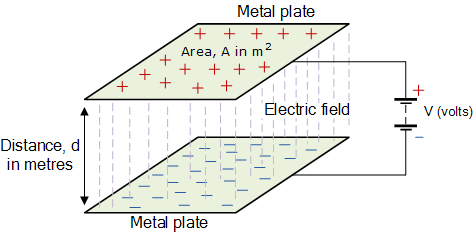

The ratio of the charge ($Q$) on the conductors to the voltage difference between the conductors ($V_C$) is known as the capacitance ($C$),

$$ C = \frac{Q}{V_C} $$

This is a *characteristic* quantity of the capacitor, which is proportional to the area of the conductors and inversely proportional to the distance between them.

### Discharging a capacitor

A common practical use for a capacitor is that of a power supply that can be quickly charged or discharged. An interesting consequence of the relationship between capacitor voltage ($V_C$) and stored charge ($Q$) is that it cannot supply a steady voltage to a circuit when used as a power supply. 

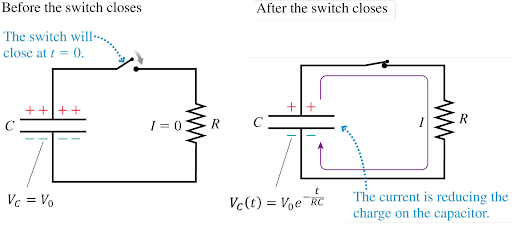

The image above shows a capacitor, charged to a voltage of $V_0$. We put this in a circuit which also contains a resistor. When we complete the circuit by closing the switch, current (moving charge) starts to flow in the circuit and this current flowing from the capacitor reduces the charge stored on the capacitor. The charge being reduced on the capacitor means that the voltage supplied to the circuit by the capacitor is also being reduced (recall $Q = V_CC$). The rate at which this decay occurs is given by

$$ V_C(t) = V_0 e^{-t/(RC)} = V_0 e^{-t/\tau},$$

where $V_0$ is the capacitor voltage at $t = 0$, which is when the switch is closed in this example, $V_C(t)$ is the **capacitor voltage** at some time $t$, $C$ is the capacitor’s capacitance and $R$ is the resistor’s resistance. This equation describes an exponential decay and it is interesting to note that, like any exponent, the exponent $t/RC$ is dimensionless (has no units). This means that the product $RC$ (known as the time constant, $\tau$) has the dimension of time! In fact, if your resistance is measured in Ohms ($\Omega$) and the capacitor is measured in Farads ($F$), the resulting product has units of seconds ($s$).

#### **Your turn #3:**

A capacitor charged to $V_0 = 2.00~\text{V}$ discharges through a resistor, with time constant $\tau = 1.0~\text{ms}$. After one time constant ($t = 1.0~\text{ms}$), the voltage has dropped to about $37\%$ of its starting value: $V_C \approx 0.37 \times 2.00~\text{V} = 0.74~\text{V}$. What is the voltage after 2 time constants?

* A. $0~\text{V}$: in the time equal to the first time constant ($\tau = 1.0~\text{ms}$), the voltage drops by about  $1.26~\text{V}$, so after another drop of that size there is nothing left.
* B. About $0.27~\text{V}$
* C. About $0.37~\text{V}$
* D. About $0.79~\text{V}$
* E. It cannot be predicted without knowing $R$ and $C$ separately.

*Your answer here*

#### Answer:

**B, about $0.27~\text{V}$.** Each time constant multiplies the voltage by the same factor, $e^{-1} \approx 0.37$, because $V_C(t+\tau) = V_0 e^{-(t+\tau)/\tau} = V_C(t)\,e^{-1}$. After two time constants:

$$ V_C = 2.00~\text{V} \times 0.37 \times 0.37 \approx 2.00~\text{V} \times 0.14 \approx 0.27~\text{V} \qquad \left(\text{exactly } 2.00~\text{V}\times e^{-2}\right). $$

* A treats the decay as dropping by the same *amount* each time constant (a straight line). It drops by the same *fraction*, so it never reaches zero.
* C multiplies by $0.37$ once and then halves. "Halving" is the habit from half-lives, but a half-life is $\tau \ln 2 \approx 0.69\,\tau$, not $\tau$.
* D multiplies by $0.63$ twice: $63\%$ is the fraction *lost* in each time constant, not the fraction kept.
* E: only the product $\tau = RC$ appears in $V_C(t)$, so $\tau$ is all you need.

### Calculating the time constant ($\tau = RC$) from a voltage decay curve

This should be familiar to you if you have experience working with exponential decays. During this lab you will use an oscilloscope (a device that measures and graphs voltage as a function of time) to observe how the capacitor voltage decays over time, the $V_C$ vs time-decay curve. Thanks to how the math of exponentials works, if you know the voltage and time of any two points along this curve, you can determine the time constant $\tau = RC$.

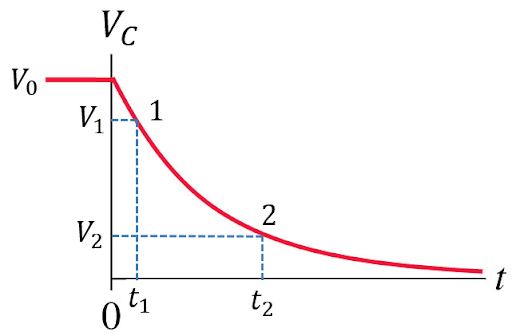

When using your oscilloscope, you will be able to directly measure the voltage at different times throughout the discharging of the capacitor. Consider two different voltages, $V_1$ and $V_2$ measured at times $t_1$ and $t_2$. We can write our exponential decay equation for each of these points,

$$ V_1 = V_0 e^{-t_1/\tau}, \text{ and}$$
$$ V_2 = V_0 e^{-t_2/\tau} .$$

Using some algebra and the rules for natural logarithms and exponentials below, demonstrate on your own that we can express $\tau$ as

$$ \tau = \frac{t_2 - t_1}{\ln (V_1/V_2)}. \;\;\; (1)$$

#### **Your turn #4:**

Grab a piece of paper and take a moment to show that you can express the time constant ($\tau$) in the format directly above. 

Here are some rules for natural logarithms and exponentials that may be of use:
1. Inverse properties:   $\ln (e^x) = x$   and   $e^{\ln x} = x$
2. Sum (logs):  $\ln (x) + \ln (y) = \ln (xy)$
3. Difference (logs):  $\ln (x) - \ln (y) = \ln (x/y)$
4. Product (exponentials): $e^x e^y = e^{x+y}$
5. Quotient (exponentials): $e^x/e^y = e^{x-y}$

#### Answer:

As explained above, the voltage decay as viewed on the oscilloscope will follow

$$ V_C(t\geq 0) = V_0 e^{-t/\tau} .$$

Note that for $t<0$ we have $V_C=V_0$, since the switch hasn't been closed yet. If we now measure two points on the curve, they are given by

$$ V_1 = V_0 e^{-t_1/\tau} $$
$$ V_2 = V_0 e^{-t_2/\tau} .$$

Dividing these two equations gives us

$$ \frac{V_1}{V_2} = \frac{V_0 e^{-t_1/\tau}}{V_0 e^{-t_2/\tau}}. $$

Note that the $V_0$'s cancel out, and by property 5 of exponentials and logarithms given above we can simplify

$$ \frac{V_1}{V_2} = \frac{e^{-t_1/\tau}}{e^{-t_2/\tau}} = \exp \left[-\frac{t_1}{\tau} - \left(-\frac{t_2}{\tau}\right) \right] = \exp\left[\frac{-t_1 + t_2}{\tau} \right] = e^{(t_2-t_1)/\tau}.$$

To isolate $\tau$ we need to take the logarithm of both sides to "undo" the exponentiation (property 1)

$$ \ln (V_1/V_2) = \ln \left(e^{(t_2-t_1)/\tau}\right) = \frac{t_2-t_1}{\tau} .$$

Now we just need to rearrange the above equation for $\tau$ and we arrive at the answer given

$$ \tau = \frac{t_2-t_1}{\ln (V_1/V_2)}. $$

Note that this worked without specifying a specific set of two points on the decay curve, meaning you can choose any two points on the curve to estimate $\tau$. You will verify this in the following section.

## Building your spreadsheet and collecting some sample data

The cell below will generate a starter spreadsheet to store some prelab data. Later you can adapt it to store your real measurements from the oscilloscope during the lab. Run the cell below. The spreadsheet already has columns for the resistance ($R$) you set and the two points you will measure on the decay curve, $(t_1, V_1)$ and $(t_2, V_2)$, each with its uncertainty.

**Note that we have filled in the uncertainties in row 0 for the purposes of Your turn #5 below, but these should not be assumed to be the uncertainties associated with any measurements you take in the lab this week.**

In [ ]:
# Run me to create an initial data entry sheet

data_entry2.sheet("prelab07_data")

Below is a simulated decay curve from a circuit set up with the following settings:

- $V_0 = 2.1 V$
- $R = (2000 \pm 20)\,\Omega$

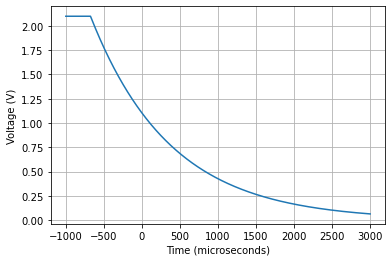

#### **Your turn #5:**

* For the purposes of this exercise, let's use $\delta t = 20\,\mu\text{s}$ for both time measurements and $\delta V = 0.02\,\text{V}$ for both voltage measurements. These have already been filled in for you. In the actual lab you will use appropriate uncertainty estimation techniques to determine the uncertainties for your measurements.
   * Notice that all times are in microseconds ($10^{-6} s$) so $\delta t1$ and $\delta t2$ were both entered as `20e-6` in the spreadsheet since the spreadsheet uses `s` as the time unit.
   * Python uses the letter `e` in a number as a shortcut for scientific notation: for e.g. `20e-6` is compiled by Python as `20*10**-6`.
* Find two points on the curve to measure voltage and time, and then enter these values into your spreadsheet above. 
   * It may seem odd that $t$ = 0 lies in the middle of the curve. We will explore this further during the in-person lab as part of learning how oscilloscopes work. For now, you only need to recognize that all of the calculations involving time actually use $\Delta t = t_2 - t_1$ (see Equation 1 above), so the location of $t$ = 0 has no impact on the calculations.
* Once you have filled out the top data row, press "Generate Vectors", and then run the cell below to see the steps of the calculation of $\tau$ and the result. You may also use this code to help you with calculations of $\tau$ in the actual lab.

#### Answer:

The easiest early point to extract is the one that crosses both grid lines at $t_1$ = -500 $\mu$s, and $V_1$ = 1.75 V.

No other points cross both grid lines. However, the point at $t_2$ = +1000 $\mu$s looks like it is approximately 3/5ths of the way between V = 0.25 V and V = 0.50 V, so we will say $V_2$ = 0.40 V.

If you use these points, you should find that you get $\tau$ = 0.00101632 s below

#### Calculating $\tau$

If all went well, you should find the code below calculates $\tau \approx 0.001~\text{s}$ based on your measurements above.
As a reminder, this means that along this exponential curve, the voltage measurement at any point is approximately 37% of what it was $\tau \approx 1000~\mu\text{s}~(\approx 0.001~\text{s})$ before that point.

In [ ]:
# Run me to calculate the time constant based on your values of t1, t2, V1
# and V2.

delta_t = t2Vec - t1Vec  # difference in time between points
W = V1Vec / V2Vec  # ratio of voltage
ln_W = np.log(W)  # np.log(x) calculates ln(x) in Python

tau = delta_t / ln_W  # calculating the time constant
print("tau =", tau, "s")

#### **Your turn #6:**

Given your calculated $\tau$ and the resistance provided above, what is the capacitance?

In [ ]:
# Use this cell to calculate C

#### Answer:

The time constant is defined as $\tau = RC$. Since we have calculated $\tau$ and set $R$ initially, we can solve for the capacitance, $C$

$$ C = \frac{\tau}{R} \approx \frac{0.001 s}{2000\Omega} = 5 \times 10^{-7} F = 0.5\ \mu F $$

## Uncertainty propagation to calculate $\delta \tau$

Now for uncertainty propagation. Recall that in the lab you will be varying $R$ and determining the associated $\tau$ using your measurements of $t_1$, $t_2$, $V_1$ and $V_2$. This will allow you to use `autofit()`, as in Prelab 06, to find the best-fit line through a $\tau$ vs. $R$ scatter plot: since $\tau = RC$, its slope is the capacitance $C$. Therefore, we need $\delta \tau$, which is the uncertainty in our y-axis variable. Looking back at our equation for $\tau$,

$$ \tau = \frac{t_2-t_1}{\ln(V_1/V_2)} $$

we can break down uncertainty propagation into four subproblems to make our lives easier. Often it is good practice to start inwards and work our way outwards in an equation when we are doing uncertainty propagation. We can immediately notice the equation involves a subtraction and a division, both of which we have encountered in this course already when it comes to uncertainty propagation.

Let's start with subproblem 1 by defining $\Delta t = t_2 - t_1$. Using the uncertainty propagation formula for addition or subtraction, we have

$$ \delta (\Delta t) = \sqrt{(\delta t_1)^2 + (\delta t_2)^2} .$$

In the denominator, we encounter subproblem 2, related to $W = V_1/V_2$. Using the uncertainty propagation formula for multiplication or division, we arrive at

$$ \delta W = W \sqrt{\left(\frac{\delta V_1}{V_1}\right)^2 + \left(\frac{\delta V_2}{V_2}\right)^2}. $$

Subproblem 3 involves a logarithm, which we haven't encountered before in uncertainty propagation, but it will continue to come up again in future labs. (This is the rule you used in Your turn #1.) Our most general equation for uncertainty propagation uses derivatives

$$ \delta f(x_1, x_2, \cdots , x_N) = \sqrt{\sum_{i=1}^N \left(\delta x_i \frac{\partial f}{\partial x_i}\right)^2}. $$

We will use the function $f(x) = \ln x$. Since this depends on only one variable, $x$, our equation above simplifies greatly

$$ \delta f(x) = \left|\delta x \frac{df}{dx}\right| .$$

Since the derivative of $\ln x$, with respect to $x$, is $1/x$, we can write $\delta f$ as

$$ \delta f(x) = \delta x\cdot \frac{d}{dx} \ln x = \frac{\delta x}{x}. $$

In our specific subproblem we are taking the logarithm of $W$, so we have

$$ \delta \ln(W) = \frac{\delta W}{W} .$$

Stepping back for a moment, we have simplified our initial equation for $\tau$ to:

$$ \tau = \frac{t_2-t_1}{\ln(V_1/V_2)} = \frac{\Delta t}{\ln W}.$$

In subproblems 1-3 we have arrived at equations for $\delta \Delta t$ and $\delta \ln W$.

Subproblem 4 is yet another division and gets us to the final form of the uncertainty equation we will be using:

$$ \delta \tau = \delta \left(\frac{\Delta t}{\ln W}\right),$$

$$ \delta \tau = \tau \sqrt{\left(\frac{\delta \Delta t}{\Delta t}\right)^2 + \left(\frac{\delta \ln W}{\ln W}\right)^2}. $$

#### **Your turn #7:**

* In the cell below we have provided the correct code to implement subproblems 1 and 2
* We have also provided the variables needed for subproblems 3 and 4, **but you need to build the correct equation using these variables.**
* Once you have completed the cell, run it to obtain a value for $\delta \tau$. You may use this code to perform your uncertainty propagation during the actual lab.

In [ ]:
# Use this cell to complete the python code for subproblems 3 and 4.

# Subproblem 1: propagation of del_delta_t
del_delta_t = np.sqrt(del_t1Vec**2 + del_t2Vec**2) 

# Subproblem 2: propagation of del_W
# - Recall that W was defined in an earlier code cell
del_W = W * np.sqrt((del_V1Vec / V1Vec)**2 + (del_V2Vec / V2Vec)**2) 

# Subproblem 3: propagation of del_ln_W
# del_ln_W = del_W + W   # correct this equation

# subproblem 4: propagation of del_delta_t/ln_W to get del_tau
# del_tau = tau + del_delta_t + delta_t + del_ln_W + ln_W  # correct this equation

print("del_tau =", del_tau, "s")
print("tau =", tau, "s")
print("Relative uncertainty del_tau/tau = ", del_tau / tau)

If you used the example data that we extracted earlier, you should find that you get

```
del_tau = [4.0182e-05] s
tau = [0.0010163] s
Relative uncertainty del_tau/tau =  [0.0395]
```

The value for $\tau$ doesn't depend on any specific $(t_1,V_1)$ and $(t_2,V_2)$ chosen, meaning you can pick any two points on the curve to get an estimate of $\tau$!

However, `del_tau` and the relative uncertainty do depend on which points you choose, so your values may differ from the ones above by up to a factor of 2 (or so). 


We use relative uncertainty to evaluate the quality of our measurements. You should find that for points spaced further apart in time, the relative uncertainty decreases, meaning we have more precision and thus a higher quality measurement. However, there are some exceptions! In particular if you make $t_2$ very large---and thus $V_2$ very small---you'll find that the relative uncertainty begins to increase again!

To get more insight into this, you can either consider the equations for the relative uncertainty in more detail, or think carefully about how the flattening of the curve at long times affects the relative uncertainty.

## Preparing your Lab 07 notebook

#### **Your turn #8:**

In this final set of tasks, you will prepare your Lab 07 notebook for data collection and analysis.

1. Open the Lab 07 Notebook and Instructions, and take a couple of minutes to read through them so that you have a sense of how you will be spending your time during the lab.
2. In Part C, you will be making one row worth of measurements in your spreadsheet, similar to the data you collected in this prelab. In Part E, you will collect further rows of data and perform your analysis.
   1. In Part C we have already included the code to copy in your prelab spreadsheet.
   2. In Part E you should collect all of the code from above needed to calculate $\tau$ and $\delta \tau$. Double-check you are getting the same results in your lab notebook as you got here.

You should now be ready for data collection and data analysis for this lab.

# Submit

Steps for submission:

1. Click: **Kernel > Restart Kernel and Run All Cells**
2. Read through the notebook to ensure all the cells executed correctly and without error.
3. Click: **File > Save and Export Notebook As > HTML**
4. Inspect your downloaded HTML document.
5. Upload the HTML document to the prelab submission assignment on Canvas.